# SJC Copula：下尾真的强于上尾吗？避险会失效吗？

接 [beyond_clayton.ipynb](beyond_clayton.ipynb)。那里的 t-Copula 检验表明，股债极端值略倾向于同日出现，
但 t-Copula 上下尾对称，回答不了中金真正的假设：**下跌时同步、上涨时不同步**。

这里用对称化 Joe-Clayton（SJC，Patton 2006）Copula。它在同一个模型里有两个参数，恰好就是
下尾相关系数 τ_L 和上尾相关系数 τ_U，于是「下尾强于上尾」可以写成正式检验：

    H0: τ_L = τ_U   vs   H1: τ_L ≠ τ_U，   LR ~ χ²(1)

| 部分 | 看的数据 | 问题 |
|---|---|---|
| A | (股, 债) | 股债**同跌**的尾部联动是否强于**同涨**？（中金假设） |
| B | (股, 1−债)，即把债券翻转 | 股票暴跌时债券是否同时大涨（**避险**），是否强于反向的「股涨债跌」？ |
| C | 滚动 250 日 | 上面两件事随时间怎么变，避险什么时候失效 |

⚠ SJC 和 Clayton 一样只能描述正相依，τ 的**水平**混有普通相关（ρ=0.3 的高斯数据也会估出 τ≈0.12）。
所以重点看**两尾之差**和不对称检验，水平只和同等相关强度的高斯基准对比着看。

## 0 · 环境与数据

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom, chi2
%run ../../01_methods.ipynb

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({
    "figure.figsize": (13, 4),
    "axes.unicode_minus": False,
    "font.sans-serif": ["PingFang SC", "Heiti TC", "Arial Unicode MS", "SimHei", "DejaVu Sans"],
})

EQUITY, BOND = "沪深300", "中债综合财富"
prices = load_prices([EQUITY, BOND]).loc["2003-01-01":]
returns = to_returns(prices)
print(f"{prices.index.min():%Y-%m-%d} ~ {prices.index.max():%Y-%m-%d}，共 {len(prices)} 个交易日")

2003-01-02 ~ 2026-10-12，共 5769 个交易日


## 1 · 校准：在已知答案的数据上检查方法

- **高斯数据**（尾部相关为 0、上下尾对称）：不对称检验的误报率应接近 5%；同时记录 SJC 估出的 τ 水平，
  作为后面「扣掉普通相关」的基准。
- **Clayton 数据**（λ_L=0.5、λ_U=0）：应估回 τ_L≈0.5、τ_U≈0，并强烈拒绝对称。

In [2]:
RHO_GRID = [0.0, 0.1, 0.2, 0.3, 0.4]
baseline = gaussian_tau_baseline(RHO_GRID, window=250, n_sims=100, seed=1)
baseline.style.format({"tau_L均值": "{:.3f}", "tau_U均值": "{:.3f}", "不对称检验误报率": "{:.1%}"})

,tau_L均值,tau_U均值,不对称检验误报率
rho,,,
0.000000,0.003,0.003,0.0%
0.100000,0.025,0.026,2.0%
0.200000,0.065,0.069,4.0%
0.300000,0.139,0.137,9.0%
0.400000,0.209,0.208,6.0%


In [3]:
rng = np.random.default_rng(0)
u, w = rng.uniform(size=3000), rng.uniform(size=3000)
v = (u ** -1.0 * (w ** -0.5 - 1) + 1) ** -1.0            # Clayton(θ=1)
pd.Series(asymmetry_test(rank_pit(u), rank_pit(v))).to_frame("Clayton(θ=1) 样本").T.round(4)

,tau_L,tau_U,tau_sym,lr,p_asym
Clayton(θ=1) 样本,0.5474,0.0001,0.3188,351.3069,0.0


股债的年度相关系数都在 −0.4 到 0.2 之间，落在误报率接近名义水平的区间。
注意高斯数据的 τ 均值随 ρ 上升：这部分 τ 与尾部无关，只是普通相关。

---
# A · 股债同跌是否强于同涨？（中金的核心假设）

逐年（互不重叠）估计 SJC。τ_L = 股债同日极端下跌的尾部相关，τ_U = 同日极端上涨。
**p 值为空**表示两尾估计都接近 0（该年股债不正相关），没有尾部可比。

In [4]:
rows = []
for year, g in returns.groupby(returns.index.year):
    if len(g) < 200:
        continue
    u, v = rank_pit(g[EQUITY].values), rank_pit(g[BOND].values)
    res = asymmetry_test(u, v)
    rho = np.corrcoef(g[EQUITY], g[BOND])[0, 1] * (1)
    rows.append({"年份": year, "ρ": rho, "τ_L": res["tau_L"], "τ_U": res["tau_U"], "p 值": res["p_asym"]})
tbl = pd.DataFrame(rows).set_index("年份")
# 同等相关强度下高斯给出的 τ（ρ≤0 时为 0），用于扣掉普通相关的贡献
tbl["高斯基准 τ"] = np.interp(tbl["ρ"].clip(lower=0), baseline.index, baseline[["tau_L均值", "tau_U均值"]].mean(axis=1))
tbl.loc[tbl["ρ"] <= 0, "高斯基准 τ"] = 0.0

tbl.style.format({"ρ": "{:.2f}", "τ_L": "{:.3f}", "τ_U": "{:.3f}", "p 值": "{:.3f}", "高斯基准 τ": "{:.3f}"},
                 na_rep="—")

,ρ,τ_L,τ_U,p 值,高斯基准 τ
年份,,,,,
2003,0.02,0.000,0.000,—,0.009
2004,0.06,0.006,0.000,—,0.016
2005,-0.12,0.000,0.000,—,0.000
2006,0.04,0.004,0.000,—,0.013
2007,0.12,0.042,0.008,0.707,0.035
2008,-0.03,0.000,0.000,—,0.000
2009,-0.01,0.000,0.043,0.274,0.000
2010,0.01,0.000,0.000,—,0.006
2011,-0.01,0.000,0.000,—,0.000


In [5]:
yearly_A = tbl.copy()

valid = tbl["p 值"].notna()
k = int(valid.sum())
lr_sum = chi2.isf(tbl.loc[valid, "p 值"].clip(lower=1e-300), 1).sum()
n_lower = int((tbl.loc[valid, "τ_L"] > tbl.loc[valid, "τ_U"]).sum())
pd.DataFrame({
    "可检验的年数（至少一尾 τ≥0.01）": [k],
    "下尾（同跌） 更强的年数": [n_lower],
    "符号检验 p 值（双侧）": [min(1.0, 2 * min(binom.cdf(n_lower, k, .5), binom.sf(n_lower - 1, k, .5)))],
    "5% 水平显著的年数": [int((tbl.loc[valid, "p 值"] < 0.05).sum())],
    "合并 LR（各年独立相加）": [lr_sum],
    "合并 p 值": [chi2.sf(lr_sum, k)],
}).T.rename(columns={0: "值"})

,值
可检验的年数（至少一尾 τ≥0.01）,5.000000
下尾（同跌） 更强的年数,3.000000
符号检验 p 值（双侧）,1.000000
5% 水平显著的年数,0.000000
合并 LR（各年独立相加）,2.425284
合并 p 值,0.787703


**判读**：股债同跌、同涨两个方向的尾部相关几乎每年都接近 0（各年股债相关都很弱或为负），
最大也只有 0.04，且与同等相关强度的高斯基准相当。少数可检验的年份里，下尾更强与上尾更强的年数相当，
合并检验远不显著。
**中金「下跌时同步、上涨时不同步」的假设在年度尺度上找不到支撑。**

---
# B · 避险：股票暴跌时债券是否同时大涨？

把债券收益翻转（v → 1−v）后，「股跌债涨」变成了左下角：
τ_L = **避险**（股票极端下跌时债券极端上涨），τ_U = **反向**（股票极端上涨时债券极端下跌）。
这里的 ρ 是翻转后的相关系数（即原相关系数取负）。

In [6]:
rows = []
for year, g in returns.groupby(returns.index.year):
    if len(g) < 200:
        continue
    u, v = rank_pit(g[EQUITY].values), rank_pit(g[BOND].values)
    res = asymmetry_test(u, 1 - v)
    rho = np.corrcoef(g[EQUITY], g[BOND])[0, 1] * (-1)
    rows.append({"年份": year, "ρ": rho, "τ_L": res["tau_L"], "τ_U": res["tau_U"], "p 值": res["p_asym"]})
tbl = pd.DataFrame(rows).set_index("年份")
# 同等相关强度下高斯给出的 τ（ρ≤0 时为 0），用于扣掉普通相关的贡献
tbl["高斯基准 τ"] = np.interp(tbl["ρ"].clip(lower=0), baseline.index, baseline[["tau_L均值", "tau_U均值"]].mean(axis=1))
tbl.loc[tbl["ρ"] <= 0, "高斯基准 τ"] = 0.0

tbl = tbl.rename(columns={"τ_L": "τ_避险（股跌债涨）", "τ_U": "τ_反向（股涨债跌）"})
tbl.style.format({"ρ": "{:.2f}", "τ_避险（股跌债涨）": "{:.3f}", "τ_反向（股涨债跌）": "{:.3f}",
                  "p 值": "{:.3f}", "高斯基准 τ": "{:.3f}"}, na_rep="—")

,ρ,τ_避险（股跌债涨）,τ_反向（股涨债跌）,p 值,高斯基准 τ
年份,,,,,
2003,-0.02,0.000,0.000,—,0.000
2004,-0.06,0.000,0.000,—,0.000
2005,0.12,0.023,0.029,0.954,0.033
2006,-0.04,0.000,0.000,—,0.000
2007,-0.12,0.000,0.000,—,0.000
2008,0.03,0.000,0.002,—,0.009
2009,0.01,0.000,0.000,—,0.006
2010,-0.01,0.001,0.000,—,0.000
2011,0.01,0.020,0.000,0.465,0.006


In [7]:
yearly_B = tbl.rename(columns={"τ_避险（股跌债涨）": "τ_L", "τ_反向（股涨债跌）": "τ_U"})
tbl = yearly_B

valid = tbl["p 值"].notna()
k = int(valid.sum())
lr_sum = chi2.isf(tbl.loc[valid, "p 值"].clip(lower=1e-300), 1).sum()
n_lower = int((tbl.loc[valid, "τ_L"] > tbl.loc[valid, "τ_U"]).sum())
pd.DataFrame({
    "可检验的年数（至少一尾 τ≥0.01）": [k],
    "避险（股跌债涨） 更强的年数": [n_lower],
    "符号检验 p 值（双侧）": [min(1.0, 2 * min(binom.cdf(n_lower, k, .5), binom.sf(n_lower - 1, k, .5)))],
    "5% 水平显著的年数": [int((tbl.loc[valid, "p 值"] < 0.05).sum())],
    "合并 LR（各年独立相加）": [lr_sum],
    "合并 p 值": [chi2.sf(lr_sum, k)],
}).T.rename(columns={0: "值"})

,值
可检验的年数（至少一尾 τ≥0.01）,10.000000
避险（股跌债涨） 更强的年数,6.000000
符号检验 p 值（双侧）,0.753906
5% 水平显著的年数,2.000000
合并 LR（各年独立相加）,14.533992
合并 p 值,0.149998


**判读**：

- 明显的避险联动只出现在 2018–2020 和 2025 年（τ≈0.17–0.22），都是股债明显负相关的年份。
  其余年份两个方向基本都是 0，**包括 2008、2015 两次股市大跌** —— 那时债券在股票极端下跌日并没有同步大涨。
- 和同等相关强度的高斯基准比，多数年份的 τ 可以由负相关本身解释；超出较多的只有 2018 年的避险（0.17 vs 0.06）
  和 2023 年的反向（0.17 vs 0.06）。
- 避险与反向谁更强并不固定：2018–2020、2025 偏「股跌债涨」，2023–2024 反而偏「股涨债跌」
  （这两年股债跷跷板主要由股票大涨日驱动）。合并检验不显著。

---
# C · 随时间的变化：滚动 250 日

每 5 个交易日重估一次。窗口相互重叠，图只用来看时间分布，不做显著性计数。

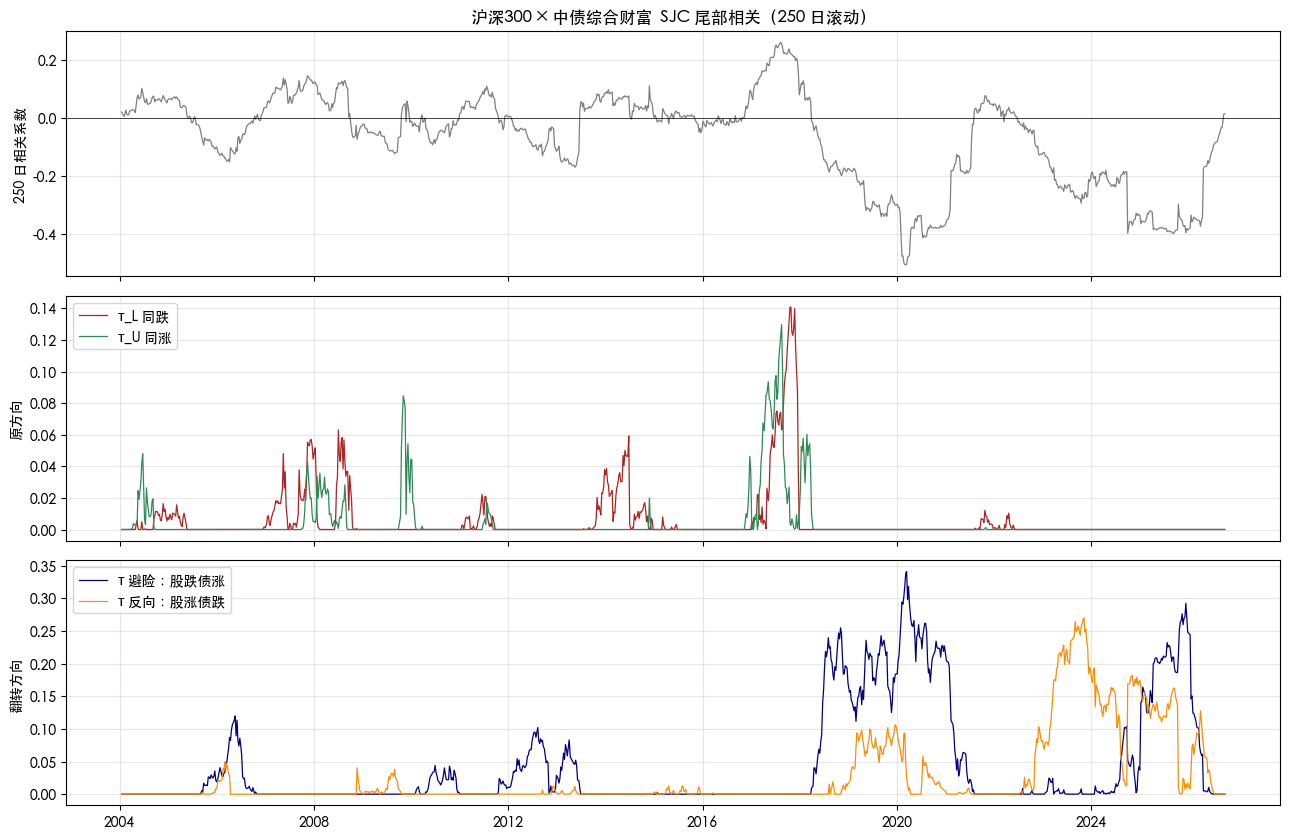

In [8]:
roll_A = rolling_asymmetry(returns[EQUITY], returns[BOND], window=250, step=5)
roll_B = rolling_asymmetry(returns[EQUITY], returns[BOND], window=250, step=5, flip_v=True)
corr = returns[EQUITY].rolling(250).corr(returns[BOND]).reindex(roll_A.index)

fig, axes = plt.subplots(3, 1, figsize=(13, 8.5), sharex=True)
axes[0].plot(corr.index, corr, color="gray", lw=.9)
axes[0].axhline(0, color="k", lw=.5); axes[0].set_ylabel("250 日相关系数")
axes[0].set_title(f"{EQUITY} × {BOND}  SJC 尾部相关（250 日滚动）")
axes[1].plot(roll_A.index, roll_A.tau_L, color="firebrick", lw=.9, label="τ_L 同跌")
axes[1].plot(roll_A.index, roll_A.tau_U, color="seagreen", lw=.9, label="τ_U 同涨")
axes[1].set_ylabel("原方向"); axes[1].legend(loc="upper left")
axes[2].plot(roll_B.index, roll_B.tau_L, color="navy", lw=.9, label="τ 避险：股跌债涨")
axes[2].plot(roll_B.index, roll_B.tau_U, color="darkorange", lw=.9, label="τ 反向：股涨债跌")
axes[2].set_ylabel("翻转方向"); axes[2].legend(loc="upper left")
for ax in axes:
    ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [9]:
summary = pd.DataFrame({
    "同跌 τ_L>0.05": [(roll_A.tau_L > 0.05).mean()],
    "同涨 τ_U>0.05": [(roll_A.tau_U > 0.05).mean()],
    "避险 τ>0.05": [(roll_B.tau_L > 0.05).mean()],
    "反向 τ>0.05": [(roll_B.tau_U > 0.05).mean()],
    "避险几乎为 0（τ<0.01）": [(roll_B.tau_L < 0.01).mean()],
}, index=["窗口占比"]).T
summary.style.format("{:.1%}")

,窗口占比
同跌 τ_L>0.05,3.7%
同涨 τ_U>0.05,3.0%
避险 τ>0.05,24.2%
反向 τ>0.05,18.2%
避险几乎为 0（τ<0.01）,64.0%


**判读**：

- 哪一组角落有尾部联动，几乎完全跟着 250 日相关系数的符号走：相关为正（如 2017–2018）时只有同跌、同涨有值，
  且两者高度相近、交替领先；相关明显为负（2018–2021、2023–2026）时只有避险、反向有值。
- 约三分之二的窗口里避险 τ 几乎为 0，即债券在股票极端下跌时没有提供可测的尾部保护。
- 截至样本末（2026 年 10 月），250 日相关系数已从 −0.4 左右回升到 0 附近，避险 τ 也随之降到 0。
- 「避险是否失效」本质上就是「股债相关是否从负转向零或正」，直接监测滚动相关系数即可。

---
# 结论

| 问题 | 结论 |
|---|---|
| 股债同跌是否强于同涨（中金假设） | **否**。两尾几乎每年都接近 0，少数可检验年份里方向不一，合并检验不显著 |
| 股票暴跌时债券是否同时大涨（避险） | **只在股债负相关的年份有**；相关为正或为零的年份没有尾部保护 |
| 避险是否强于反向 | **不一定**。2018–2020、2025 偏避险，2023–2024 偏「股涨债跌」，合并不显著 |
| 尾部联动方向由什么决定 | 几乎完全由滚动相关系数的符号决定 |

和前两个 notebook 合起来：在沪深300 × 中债综合财富上，用多种 Copula（Clayton/Gumbel、t、SJC）都找不到
「超出普通相关、且偏向下跌」的尾部联动。对股债配置真正有用的信息是股债相关系数本身的时变 ——
它决定了债券在股票极端下跌时能否起到保护作用。

In [10]:
print("A 可检验年数", int(yearly_A["p 值"].notna().sum()), "；B 可检验年数", int(yearly_B["p 值"].notna().sum()))
print(f"滚动窗口中避险几乎为 0 的占比 {(roll_B.tau_L < 0.01).mean():.1%}")

A 可检验年数 5 ；B 可检验年数 10
滚动窗口中避险几乎为 0 的占比 64.0%
